4. Time series analysis
Menganalisis tren bulanan dan perubahan delivery performance. Cari lonjakan, pola yang bertahan, dan periode yang memerlukan investigasi.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [2]:
data_path = Path("../../Data/Processed/dataco_cleaned.csv")

if not data_path.exists():
    raise FileNotFoundError(
        f"Processed dataset not found{data_path}\n"
    )

df = pd.read_csv(
    data_path,
    low_memory=False,
    parse_dates= [
        "order date (DateOrders)",
        "shipping date (DateOrders)"
    ],
)

print(f"loaded file: {data_path}")
print(f"rows:{len(df):,}")
print(f"columns: {df.shape[1]}")


loaded file: ../../Data/Processed/dataco_cleaned.csv
rows:180,519
columns: 64


In [3]:
#monthly summary

monthly_analysis = df[
    df["delivery_timing"].isin(
        ["Delayed", "Not delayed", "Canceled"]
    )
].copy()

monthly_analysis["order_year_month"] = pd.to_datetime(
    monthly_analysis["order_year_month"].astype(str)
)

monthly_summary = (
    monthly_analysis
    .groupby("order_year_month")
    .agg(
        total_items=("Order Item Id", "count"),
        delayed_items=("delivery_timing",lambda s: (s == "Delayed").sum()),
        on_time_or_early_items=("delivery_timing",lambda s: (s == "Not delayed").sum()),
        canceled_items=("delivery_timing",lambda s: (s == "Canceled").sum())
    ).reset_index()
)

monthly_summary["eligible_items"] = (monthly_summary["delayed_items"]+ monthly_summary["on_time_or_early_items"])
monthly_summary["delay_rate_pct"] = (monthly_summary["delayed_items"]/ monthly_summary["eligible_items"]* 100)
monthly_summary["cancellation_rate_pct"] = (monthly_summary["canceled_items"]/ monthly_summary["total_items"]* 100)
display(monthly_summary.round(2))

/tmp/ipykernel_29219/658416498.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_summary.round(2))


,order_year_month,total_items,delayed_items,on_time_or_early_items,canceled_items,eligible_items,delay_rate_pct,cancellation_rate_pct
0,2015-01-01,5322,2880,2234,208,5114,56.32,3.91
1,2015-02-01,4729,2594,1893,242,4487,57.81,5.12
2,2015-03-01,5362,2936,2191,235,5127,57.27,4.38
3,2015-04-01,5126,2760,2155,211,4915,56.15,4.12
4,2015-05-01,5357,2951,2136,270,5087,58.01,5.04
5,2015-06-01,5134,2778,2130,226,4908,56.60,4.40
6,2015-07-01,5299,2939,2185,175,5124,57.36,3.30
7,2015-08-01,5273,2936,2089,248,5025,58.43,4.70
8,2015-09-01,5140,2914,2012,214,4926,59.16,4.16
9,2015-10-01,5302,2906,2167,229,5073,57.28,4.32


Delay rate tidak menunjukkan trend perbaikan yang konsisten,
pada september 2015 delay rate mencapai 59,16% , juni 2016 mencapai 59.31% dan ini yang tertinggi, juli 2016 turun ke 55,17% , januari 2018 kembali ke 58,66%

<function matplotlib.pyplot.show(close=None, block=None)>

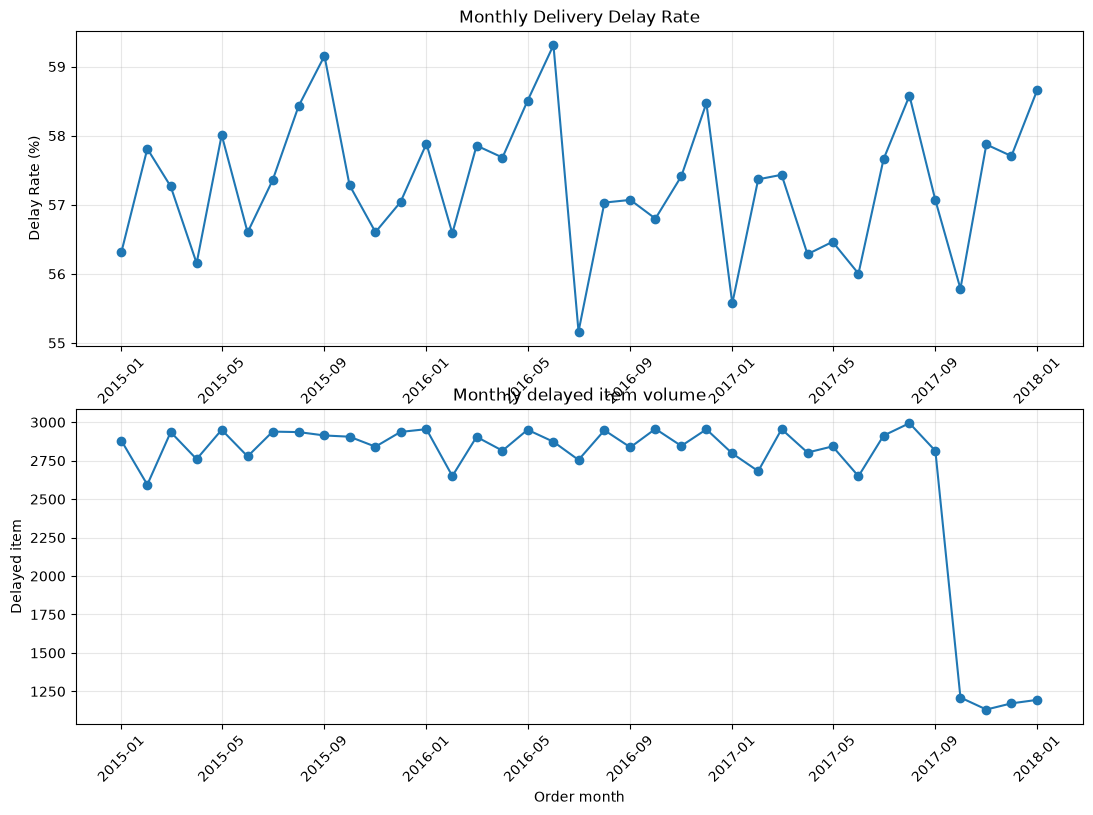

In [4]:
fig, axes= plt.subplots(2,1 , figsize=(13,9))

axes[0].plot(
    monthly_summary["order_year_month"],
    monthly_summary["delay_rate_pct"],
    marker="o"
)

axes[0].set_title("Monthly Delivery Delay Rate")
axes[0].set_ylabel("Delay Rate (%)")
axes[0].set_xlabel("Order Month")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    monthly_summary["order_year_month"],
    monthly_summary["delayed_items"],
    marker="o"
)

axes[1].set_title("Monthly delayed item volume")
axes[1].set_ylabel("Delayed item")
axes[1].set_xlabel("Order month")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(True, alpha=0.3)

plt.tight_layout
plt.show

Penurunan signifikan delay rate di bulan juli 2016 yaitu di 55,1% dan titik tertinggi delay rate pada juni 2016 di 59,3%. perubahan drastis volume barang terlambat pada akhir 2017 terdapat penurunan drastis mendadak turun 1,100 - 1,200 barang dari yang awalnya 2,600- 3,000 barang / bulan 

In [5]:
#Check the date range

print("earlier order date:", df["order_date"].min())
print("latest order date:", df["order_date"].max())

year_summary = (
    df.groupby("order_year")
    .agg(
        total_items=("Order Item Id", "count"),
        first_order_date=("order_date", "min"),
        last_order_date=("order_date", "max"),
        active_months=("order_year_month", "nunique")
    ).reset_index()
)
display(year_summary)

earlier order date: 2015-01-01 00:00:00
latest order date: 2018-01-31 00:00:00


,order_year,total_items,first_order_date,last_order_date,active_months
0,2015,62650,2015-01-01 00:00:00,2015-12-31 00:00:00,12
1,2016,62550,2016-01-01 00:00:00,2016-12-31 00:00:00,12
2,2017,53196,2017-01-01 00:00:00,2017-12-31 00:00:00,12
3,2018,2123,2018-01-01 00:00:00,2018-01-31 00:00:00,1


2015 total item 62,650 data mencakup 12 bulan,
2016 total item 62,550 data mencakup 12 bulan,
2017 total item 53,196 data mencakup 12 bulan tetapi volume turun pada oktober,
2018 total item 2,123 data mencakup 1 bulan.

In [6]:
df["order_month_start"] = (pd.to_datetime(df["order_date"]).dt.to_period("M").dt.to_timestamp())

monthly_volume_check = (
    df.groupby("order_month_start")
        .agg(
        total_items=("Order Item Id", "count"),
        first_order_date=("order_date", "min"),
        last_order_date=("order_date", "max")
    ).reset_index()
)

display(monthly_volume_check.tail(8))

,order_month_start,total_items,first_order_date,last_order_date
29,2017-06-01,4951,2017-06-01 00:00:00,2017-06-30 00:00:00
30,2017-07-01,5318,2017-07-01 00:00:00,2017-07-31 00:00:00
31,2017-08-01,5305,2017-08-01 00:00:00,2017-08-31 00:00:00
32,2017-09-01,5189,2017-09-01 00:00:00,2017-09-30 00:00:00
33,2017-10-01,2255,2017-10-01 00:00:00,2017-10-31 00:00:00
34,2017-11-01,2055,2017-11-01 00:00:00,2017-11-30 00:00:00
35,2017-12-01,2124,2017-12-01 00:00:00,2017-12-31 00:00:00
36,2018-01-01,2123,2018-01-01 00:00:00,2018-01-31 00:00:00
